# HAH913E – Physical Activity Assignment

**GitHub repository:** [GitHub Repository](PASTE_GITHUB_URL_HERE)

**Team members:**
- Faraj Tania
- Mussotte Sarah
- Vigneau-Sugar Thomas


## 1. Loading the accelerometer data

The dataset contains accelerometer measurements along the x, y, and z axes, expressed in g. The time variable `t` is expressed in seconds.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = np.loadtxt("0_z.csv", delimiter=",", skiprows=2)

t = data[:, 0]
x = data[:, 1]
y = data[:, 2]
z = data[:, 3]

print(data.shape)
print(data[:5])

(21000, 4)
[[ 0.     -0.0938 -0.0156  0.9531]
 [ 0.02   -0.0938 -0.0156  0.9531]
 [ 0.04   -0.0938 -0.0156  0.9531]
 [ 0.06   -0.0938 -0.0156  0.9531]
 [ 0.08   -0.0938 -0.0156  0.9531]]


## 2. Computing ENMO

ENMO (Euclidean Norm Minus One) combines the acceleration measured along the three axes into a single value.

First, the vector magnitude of the acceleration is calculated as:

$$
VM = \sqrt{x^2 + y^2 + z^2}
$$

The gravitational component of 1 g is then subtracted:

$$
ENMO = \sqrt{x^2 + y^2 + z^2} - 1
$$

For this assignment, the resulting ENMO values are kept without truncating negative values, in order to reproduce the provided reference plots.

In [3]:
def calculate_enmo(x, y, z):
    return np.sqrt(x**2 + y**2 + z**2) - 1

enmo = calculate_enmo(x, y, z)

In [4]:
print(enmo[:5])
print("Minimum ENMO:", enmo.min())
print("Maximum ENMO:", enmo.max())

[-0.04216838 -0.04216838 -0.04216838 -0.04216838 -0.04216838]
Minimum ENMO: -0.8894933486164747
Maximum ENMO: 12.784615518758585


## 3. ENMO over time

The calculated ENMO values can be represented over time to visualize changes in physical activity throughout the recording.

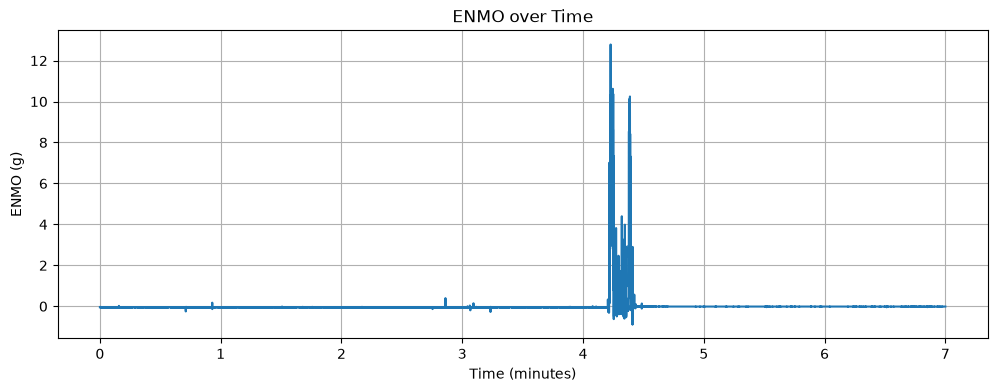

In [5]:
time_minutes = t / 60

plt.figure(figsize=(12, 4))
plt.plot(time_minutes, enmo)

plt.xlabel("Time (minutes)")
plt.ylabel("ENMO (g)")
plt.title("ENMO over Time")
plt.grid(True)

plt.show()

## 4. ENMO integration over epochs

The ENMO signal is divided into fixed-length epochs of 10, 30, and 60 seconds.

For each epoch, the ENMO values are summed and scaled by the epoch duration expressed in minutes:

$$
I_T =
\left(
\sum_{i=1}^{N} ENMO_i
\right)
\frac{T}{60}
$$

where:

- $I_T$ is the integrated ENMO for an epoch,
- $T$ is the epoch length in seconds,
- $N$ is the number of samples in that epoch.

The same calculation is applied for epoch lengths of 10 s, 30 s, and 60 s.

In [6]:
fs = 1 / (t[1] - t[0])

print("Sampling frequency:", fs, "Hz")

Sampling frequency: 50.0 Hz


In [7]:
def integrate_enmo(enmo, epoch_seconds, fs):
    samples_per_epoch = int(epoch_seconds * fs)
    n_epochs = len(enmo) // samples_per_epoch

    integrated = []

    for i in range(n_epochs):
        start = i * samples_per_epoch
        end = start + samples_per_epoch
        epoch = enmo[start:end]

        value = np.sum(epoch) * (epoch_seconds / 60)
        integrated.append(value)

    return np.array(integrated)

## 5. Visualization for different epoch lengths

The integrated ENMO is plotted for epoch lengths of 10, 30, and 60 seconds. The original ENMO signal is shown below each integrated representation to compare the accumulated activity with the signal over time.

In [8]:
def plot_enmo_epoch(t, enmo, epoch_seconds, fs):
    integrated = integrate_enmo(enmo, epoch_seconds, fs)

    epoch_times = np.arange(len(integrated)) * epoch_seconds / 60
    epoch_width = epoch_seconds / 60

    plt.figure(figsize=(10, 6))

    plt.subplot(2, 1, 1)
    plt.bar(epoch_times, integrated, width=epoch_width * 0.9, align="edge")
    plt.ylabel("Integrated ENMO (g.min)")
    plt.title(f"ENMO integrated over {epoch_seconds:.1f} s intervals")

    plt.subplot(2, 1, 2)
    plt.plot(t / 60, enmo)
    plt.xlabel("Time (minutes)")
    plt.ylabel("ENMO (g)")
    plt.title("ENMO over Time")

    plt.tight_layout()
    plt.show()

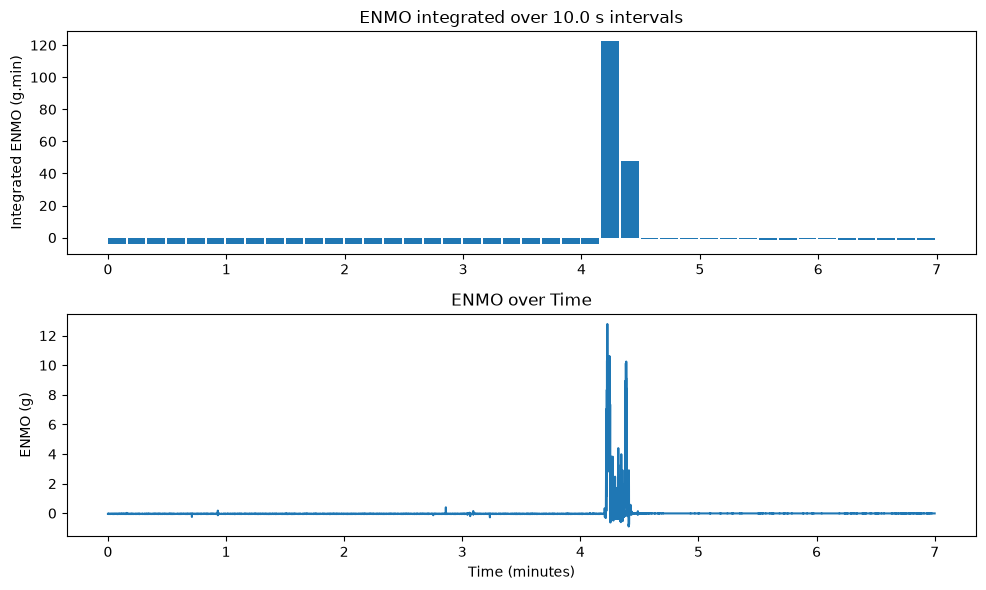

In [9]:
plot_enmo_epoch(t, enmo, 10, fs)

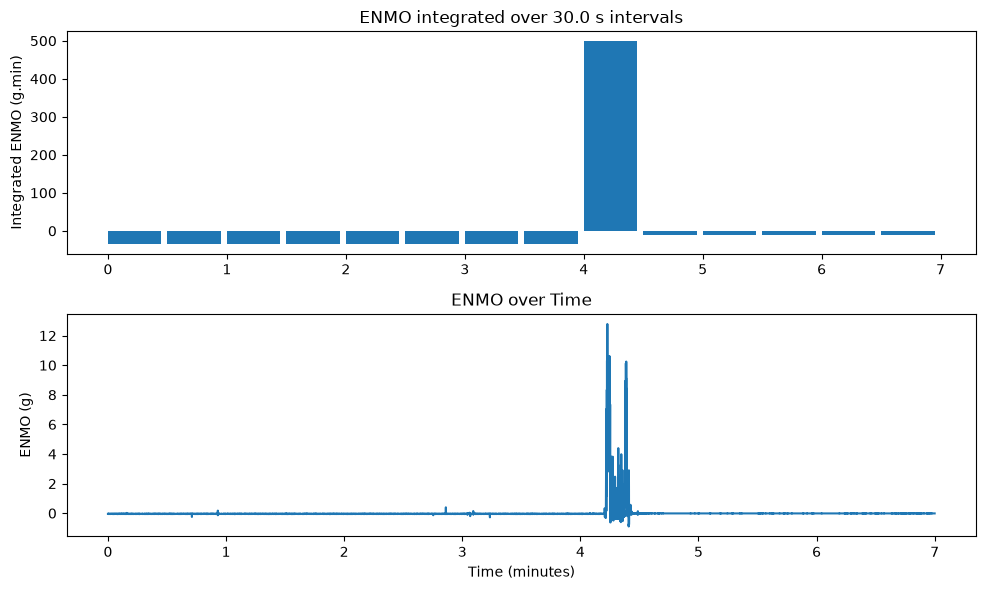

In [10]:
plot_enmo_epoch(t, enmo, 30, fs)

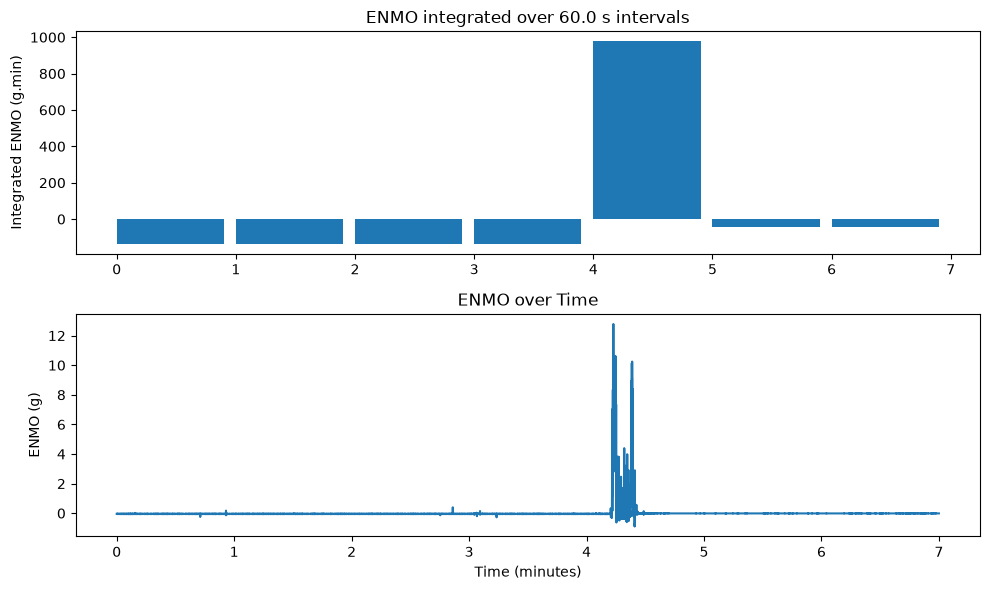

In [11]:
plot_enmo_epoch(t, enmo, 60, fs)

## AI prompts

### Prompt 1
"What is the formula for ENMO using tri-axial accelerometer data x, y, and z?"



### Prompt 2
"What does 'integrate ENMO over epoch' mean?"

**After review:**  
The proposed method was compared with the reference plots and adapted to match the required 10 s, 30 s, and 60 s outputs.

### Prompt 3
"Should negative ENMO values be set to zero?"

**After review:**  
This approach was tested but not retained because it did not reproduce the reference plots provided in the assignment.